In [2]:
from scipy import stats
from scipy.stats import norm
import numpy as np
import argparse
import matplotlib.pyplot as plt
import scipy as sp
import time
from scipy.stats import poisson
from collections import Counter
import pickle
import pandas as pd
import sys
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.optimize import root_scalar
import cvxpy as cp

## Priors: Multiple different "classes" of priors for Bayesian version of heteroskedastic mean estimation problem


In [3]:
### Two-point adversarial prior
def two_point_adversarial_prior(mu, si_min, si_max, m, n):
  assert m < n, f"Assertion failed: m ({m}) is not less than n ({n})"
  scales = np.random.choice([si_min, si_max], size=n, p=[(m/n), 1-(m/n)])
  rng = np.random.default_rng()
  return rng.normal(mu*np.ones(n), scales)

### Two-point \alpha-mixture prior (Po Ling-Loh)
def two_point_alpha_adversarial_prior(si_min, alpha, n):
  return two_point_adversarial_prior(1, n**(2*alpha), np.floor(np.log(n)), n)

### General scale mixture of Gaussians sampling
def sample_scale_mixture(mu, prior_atoms, prior_weights, n=1, rng=None):
    scales = np.asarray(prior_atoms)
    weights = np.asarray(prior_weights)
    if rng is None:
        rng = np.random.default_rng()
    # Choose component indices according to weights
    comps = rng.choice(len(weights), size=n, p=weights)
    return rng.normal(mu*np.ones(n), scales[comps])

### Subset-of-signals prior:
# select \approx m variances in interval [si_min, 1] and \approx n-m variances in interval [1, si_max]

def subset_of_signals_adversarial_prior(mu, si_min, si_max, m, n):
  if not (0 <= m/n <= 1):
    raise ValueError("Probability q must be between 0 and 1.")
  if not (si_min <= 1 <= si_max):
    raise ValueError("Condition si_min <= 1 <= K must be met for valid intervals.")
  scales = np.zeros(n)
  r = np.random.rand(n)
  idx_interval1 = (r < (m/n))
  idx_interval2 = ~idx_interval1
  scales[idx_interval1] = np.random.uniform(si_min, 1, size=np.sum(idx_interval1))
  scales[idx_interval2] = np.random.uniform(1, si_max, size=np.sum(idx_interval2))
  rng = np.random.default_rng()
  return rng.normal(mu*np.ones(n), scales)

def generate_data_from_prior(prior_atoms, prior_weights, mu, n, rng=None):
  sig = np.random.choice(prior_atoms, size=n, p=prior_weights)
  if rng is None:
      rng = np.random.default_rng()
  return rng.normal(mu*np.ones(n), sig), sig

## Code implementing external algorithms known in the literature

In [4]:
########### Algorithms from literature we will compare with NPMLE ###############

# Median (standard)
def median_estimator(N_obs):
  return np.median(N_obs)

# k-median estimator
def k_median_interval(N_obs, k, rule = "midpoint"):
    """
    Compute (theta_med_minus_k, theta_med_k) for the k-median,
    using the definition based on psi_n.

    Parameters
    ----------
    N_obs : array_like, shape (n,)
        Data.
    k : int
        Nonnegative integer <= n. Typically k <= n/2.

    Returns
    -------
    theta_minus_k : float
        hat{theta}_{med,-k}
    theta_k : float
        hat{theta}_{med,k}
    """
    x = np.sort(np.asarray(N_obs, dtype=float))
    n = x.size
    if not (0 <= k <= n):
        raise ValueError("k must satisfy 0 <= k <= n.")
    else:
      # order-statistic indices (1-based)
      j_left  = int(np.floor((n - k) / 2.0))
      j_right = int(np.ceil((n + k) / 2.0))

      # convert to 0-based Python indices, clamp for safety
      j_left  = max(1, min(j_left, n))  - 1
      j_right = max(1, min(j_right, n)) - 1

      theta_minus_k = x[j_left]
      theta_k = x[j_right]
      if rule == "midpoint":
          return 0.5 * (theta_minus_k + theta_k)
      elif rule == "left":
          return theta_minus_k
      elif rule == "right":
          return theta_k
      else:
          raise ValueError("Unknown rule for k_median.")

# MLE estimator under oracle knowledge of the full list of variances
def oracle_estimator(N_obs, N_vars):
  N_inv_vars = 1 / N_vars
  dot_prod = np.dot(N_inv_vars, N_obs)
  norm_inv_Y = np.linalg.norm(N_inv_vars)
  return dot_prod / norm_inv_Y

import numpy as np
import math

def phi_interval(x, a, b):
    """φ(x; [a,b]) = a if x < a; x if a <= x <= b; b if x > b."""
    return np.clip(x, a, b)

# Iterative truncation estimator
def iterative_truncation_estimator(N_obs, B, mu0, mu_star=None, m=1.0, n=None, return_path=False):
    """
    Mean Estimation via Iterative Truncation (Algorithm 1).

    Parameters
    ----------
    X : array_like, shape (n,)
        Observations {x_i}.
    B : float
        Initial radius parameter; assumed to satisfy B >= 2|mu0 - mu*|.
    mu0 : float
        Initial estimate μ_0.
    mu_star : float, optional
        True mean μ*, not used in the algorithm (only in the assumption).
    m : float
        Parameter m appearing in T = ceil(64 n ln n / m).
    n : float or int, optional
        Number of samples. If None, taken as len(X).
    return_path : bool
        If True, also return all stage-wise estimates for debugging.

    Returns
    -------
    mu_hat : float
        Final estimate hat{μ} = μ^{(K)}_{T+1}.
    history : list of float, optional
        If return_path=True, list of intermediate μ values.
    """
    X = np.asarray(N_obs, dtype=float)
    if n is None:
        n = X.shape[0]
    else:
        n = int(n)
        if n != X.shape[0]:
            raise ValueError("Provided n does not match len(X).")
    # Initialization
    delta = float(B)          # δ^(0)
    mu_k0 = float(mu0)        # μ_0^(0)
    # K = ceil(log2 δ^(0)); safeguard δ <= 1
    if delta <= 1.0:
        K = 0
    else:
        K = int(math.ceil(math.log2(delta)))
    # T = ceil(64 n ln n / m), ensure at least 1
    T = max(1, int(math.ceil(64.0 * n * math.log(n) / m)))

    history = []
    for k in range(K + 1):
        mu_t = mu_k0
        for _ in range(T + 1):
            a = mu_t - delta
            b = mu_t + delta
            # φ applied to all x_i at once
            truncated = phi_interval(X, a, b)
            # μ_{t+1}^{(k)} = (1/n) * sum_i φ(x_i; Δ_t^{(k)})
            mu_t = truncated.mean()
            if return_path:
                history.append(mu_t)
        # Prepare for next stage
        mu_k0 = mu_t              # μ_0^{(k+1)} = μ_{T+1}^{(k)}
        delta = delta / 2.0       # δ^{(k+1)} = δ^{(k)} / 2
    mu_hat = mu_t  # μ_{T+1}^{(K)}
    if return_path:
        return mu_hat, history
    return mu_hat

# r-modal estimator of Chernoff

# k-shortest interval estimator (Po Ling-Loh et al., 2019)
def k_shorth_interval_estimator(N_obs, N_vars):
  return 0

# hybrid estimator (Po Ling-Loh et al., 2019)
def hybrid_estimator(N_obs, N_vars):
  return 0



## ChatGPT Recommendations

In [12]:
import numpy as np
from scipy import optimize as opt
from scipy.stats import norm


############################ NPMLE estimator ##################################
# Mixture of 1D Gaussians with common location mu and random scale.

"""
def mixture_density(prior_atoms, prior_weights, mu, obs):
    Vectorized mixture density f_{G,mu}(obs).

    prior_atoms : (K,)  array of scales (sigma_k > 0)
    prior_weights : (K,) array of weights
    mu : float
    obs : scalar or array-like (n,)

    Returns
    -------
    f : float if obs is scalar, or ndarray shape (n,) if obs is array.
    sigma = np.asarray(prior_atoms, dtype=float)
    w = np.asarray(prior_weights, dtype=float)
    obs = np.asarray(obs, dtype=float)

    if obs.ndim == 0:
        # scalar case
        comp = norm.pdf(obs, loc=mu, scale=sigma)  # (K,)
        return float(np.dot(comp, w))
    else:
        # vector case: shape (n, K)
        comp = norm.pdf(obs[:, None], loc=mu, scale=sigma[None, :])
        return comp @ w  # (n,)
"""

def mixture_density(prior_atoms, prior_weights, mu, obs):
    """
    Vectorized mixture density f_{G,mu}(obs).

    prior_atoms   : (K,) array of scales
    prior_weights : (K,) array of weights
    mu            : scalar or (M,) array
    obs           : scalar or (n,) array

    Returns
    -------
    f :
      - scalar if mu and obs are scalar
      - (n,) if mu scalar, obs vector
      - (M,) if mu vector, obs scalar
      - (M, n) if mu vector, obs vector
    """
    sigma = np.atleast_1d(np.asarray(prior_atoms, dtype=float))      # (K,)
    w = np.atleast_1d(np.asarray(prior_weights, dtype=float))        # (K,)
    mu = np.atleast_1d(np.asarray(mu, dtype=float))                  # (M,)
    obs = np.atleast_1d(np.asarray(obs, dtype=float))                # (n,)

    # component densities: shape (M, n, K)
    comp = norm.pdf(
        obs[None, :, None],           # (1, n, 1)
        loc=mu[:, None, None],        # (M, 1, 1)
        scale=sigma[None, None, :]    # (1, 1, K)
    )

    # mixture sum over K
    dens = np.sum(comp * w[None, None, :], axis=-1)  # (M, n)

    # squeeze back to intuitive shapes
    if dens.shape[0] == 1:
        dens = dens[0]
    if dens.ndim == 1 and dens.shape[0] == 1:
        dens = float(dens)

    return dens

def avg_loglikelihood(prior_atoms, prior_weights, mu, N_obs):
    """
    Average log-likelihood of the mixture for observations N_obs.
    """
    N_obs = np.asarray(N_obs, dtype=float)
    dens = mixture_density(prior_atoms, prior_weights+1e-10, mu, N_obs)+1e-20  # (n,)
    return np.mean(np.log(dens), axis = -1)


# gradient of D_{G}(\si;\mu)
"""
    D_G(sigma; mu) = (1/n) sum_i [ (1/sigma)*phi((X_i-mu)/sigma) / f_G_mu(X_i) ]
    where f_G_mu(x) = sum_j w_j * N(x | mu, prior_atoms[j]^2).

    We compute the derivative w.r.t. sigma of D_G
"""
def DG_sigma(prior_atoms, prior_weights, sigma, mu, N_obs, denom=None):
    """
    D_G(sigma; mu) = (1/n) sum_i [ (1/sigma)*phi((X_i-mu)/sigma) / f_G_mu(X_i) ]
    where f_G_mu(x) = sum_j w_j * N(x | mu, prior_atoms[j]^2).
    """
    # N_obs = np.asarray(N_obs, dtype=float)
    # if denom is None:
    #     denom = mixture_density(prior_atoms, prior_weights, mu, N_obs)  # (n,)
    # z = (N_obs - mu) / sigma
    # num = (1.0 / sigma) * norm.pdf(z)
    # return np.mean(num / denom)

    N_obs = np.asarray(N_obs, dtype=float)

    sigma_arr = np.atleast_1d(np.asarray(sigma, dtype=float))
    scalar_input = np.isscalar(sigma) or sigma_arr.shape == ()

    if denom is None:
        denom = mixture_density(prior_atoms, prior_weights, mu, N_obs)  # (n,)
    denom = np.asarray(denom, dtype=float)

    z = (N_obs[None, :] - mu) / sigma_arr[:, None]          # (m, n)
    num = (1.0 / sigma_arr[:, None]) * norm.pdf(z)          # (m, n)

    out = np.mean(num / (denom[None, :] + 1e-20), axis=1)             # (m,)

    return out[0] if scalar_input else out

def grad_DG_sigma(prior_atoms, prior_weights, sigma, mu, N_obs, denom=None):
    """
    Gradient of D_G(sigma; mu) with respect to sigma.

    prior_atoms : (K,) scales of mixture
    prior_weights : (K,) weights
    sigma : scalar (the sigma we are differentiating in D_G)
    mu : scalar
    N_obs : (n,) data array
    denom : optional (n,) array f_G_mu(X_i); if None, computed here.

    Returns
    -------
    float : gradient value at sigma
    """
    N_obs = np.asarray(N_obs, dtype=float)

    if denom is None:
        denom = mixture_density(prior_atoms, prior_weights, mu, N_obs)  # (n,)

    z = (N_obs - mu) / sigma
    num = (1.0 / sigma**2) * norm.pdf(z) * (z**2 - 1) # (n,)

    return np.mean(num / denom)


def update_atoms(atoms, weights, mu, N_obs, si_min, si_max):
    """
    Update the atom set by finding a new sigma that is a root of DG_sigma(sigma) - 1.
    Uses [si_min, si_max] as the bracket for sigma.
    """
    atoms = np.asarray(atoms, dtype=float)
    weights = np.asarray(weights, dtype=float)
    N_obs = np.asarray(N_obs, dtype=float)
    min_N_obs = np.min(np.abs(N_obs))
    max_N_obs = np.max(np.abs(N_obs))
    # Precompute denominator f_G_mu(X_i) once for current atoms/weights
    denom = mixture_density(atoms, weights, mu, N_obs)  # (n,)

    fn = lambda s: DG_sigma(atoms, weights, s, mu, N_obs, denom)
    grad_fn = lambda s: grad_DG_sigma(atoms, weights, s, mu, N_obs, denom)

    new_atom_found = False
    new_atom = None
    try:
        # Check if the bracket is valid before calling root_scalar
        val_at_min = fn(min_N_obs)
        val_at_max = fn(max_N_obs)
        # print(val_at_min, val_at_max)
        # if np.isnan(val_at_min) or np.isnan(val_at_max) or np.sign(val_at_min) == np.sign(val_at_max):
            # If the signs are the same or values are NaN, brentq will fail.
            # We indicate no new atom was found via root-finding.
            # pass # new_atom remains None

        # else:
            # Root-finding in [si_min, si_max]
            # log = []
            # def grad_fn_logged(s):
            #     value = grad_fn(s)
            #     print(f"root_scalar eval {len(log)+1}: s={s}, grad={value}")
            #     log.append({"s": s, "grad": value})
            #     return value
        res = opt.brute(
                grad_fn,
                ranges = [(si_min, si_max)],
                Ns=3000,
                full_output=True   # optional, gives RootResults with metadata
            )
        obj_val = res[1]
        new_atom = res[0]
        # print(new_atom, obj_val)
        new_atom_found = True

    except (ValueError, RuntimeError) as e:
        # Catch errors from root_scalar (e.g., if f(a) and f(b) have same signs, or other numerical issues)
        pass # new_atom remains None

    if new_atom_found and new_atom is not None:
        # Avoid exact-duplicate atoms (with tolerance)
        if not np.any(np.isclose(atoms, new_atom, atol=1e-12)):
            atoms = np.concatenate((atoms, new_atom))

    return atoms

def update_atoms_grid(atoms,weights,mu,N_obs,si_min,si_max,verbose=False):
    x = np.linspace(si_min, si_max, 500) # WARNING: 500 is somewhat arbitrary
    y = DG_sigma(atoms,weights,x,mu,N_obs)
    new_atom = x[np.argmax(y)]

    # new_atom = result.x
    if verbose:
        print(f"max FOC: ", np.max(y))

    if new_atom not in atoms:
        new_atoms = np.append(atoms, new_atom)
    else:
        new_atoms = atoms

    return np.sort(new_atoms)

def get_weights_npmle(atoms, weights, mu, N_obs):
    """
    Optimize mixture weights for fixed atoms and mu via L-BFGS-B,
    maximizing the average log-likelihood.

    Returns
    -------
    opt_success : bool
    weights_hat : (K,) array, normalized
    """
    atoms = np.asarray(atoms, dtype=float)
    N_obs = np.asarray(N_obs, dtype=float)

    Phi = norm.pdf(N_obs[:, None], loc=mu, scale=atoms[None, :])

    def target(w):
        # L-BFGS-B works better if we keep it unconstrained but penalize invalid regions
        w = np.asarray(w, dtype=float)
        # if np.any(w < 0):
        #     return np.inf
        # if w.sum() <= 0:
        #     return np.inf
        # w = w / w.sum()
        # negative average log-likelihood (we minimize this)
        dens = Phi @ (w+1e-10) + 1e-20
        ret = np.mean(np.log(dens))
        return -ret + np.log(np.sum(w) + 1e-10)

    def jac(w):
        w = np.asarray(w, dtype=float)
        dens = Phi @ (w+1e-10) + 1e-20
        grad = Phi.T @ (1/dens) / len(N_obs)
        return -grad + 1/(np.sum(w)+1e-10)


    opt_success = False
    number_ls = 20
    opt_options = {'maxiter': int(number_ls)}
    max_tries = 3
    it = 0

    # Start from uniform weights over the current atoms
    # weights0 = np.ones(len(atoms), dtype=float) / len(atoms)
    weights0 = weights / weights.sum()
    m = len(atoms)
    # print(weights0)
    while (not opt_success) and (it < max_tries):
        result = sp.optimize.minimize(
            target,
            weights0,
            jac=jac,
            method='L-BFGS-B',
            tol=1e-10,
            bounds=sp.optimize.Bounds(1e-10+np.zeros(m), np.inf + np.zeros(m), True))
        if not result.success:
            number_ls *= 3
            print("Weight optimization failed. Increase maxls to ", number_ls)
            opt_options = {'maxls': int(number_ls), 'maxfun': int(1e6)}
            it += 1
        else:
            opt_success = True

    if not opt_success:
        print("Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.")
        return opt_success, weights0
    else:
        return opt_success, result.x / np.sum(result.x)


# alternative if FW / L-BFGS-B fails
def get_weights_npmle_EM(x, scales, mu=0.0, w_init=None,
                         max_iter=200, tol=1e-8):
    """
    EM for a 1D Gaussian scale mixture with fixed mu and scales,
    optimizing only the mixture weights.

    Model: X ~ sum_k w_k * N(mu, scales[k]**2)

    Parameters
    ----------
    x : array_like, shape (n,)
        Observations.
    scales : array_like, shape (K,)
        Fixed standard deviations sigma_k > 0.
    mu : float
        Fixed location parameter.
    w_init : array_like, shape (K,), optional
        Initial weights; if None, use uniform.
    max_iter : int
        Maximum EM iterations.
    tol : float
        Stop when change in weights has L1 norm < tol.

    Returns
    -------
    w : ndarray, shape (K,)
        Estimated mixture weights (MLE).
    loglik_hist : list of float
        Log-likelihood values over iterations.
    """
    x = np.asarray(x, dtype=float)
    sigma = np.asarray(scales, dtype=float)
    n = x.size
    K = sigma.size

    if w_init is None:
        w = np.ones(K) / K
    else:
        w = np.asarray(w_init, dtype=float)
        w = w / w.sum()

    loglik_hist = []

    for _ in range(max_iter):
        # E-step: responsibilities r_{ik}, shape: (n, K)
        comp_dens = norm.pdf(x[:, None], loc=mu, scale=sigma[None, :])  # n x K
        numer = w[None, :] * comp_dens  # n x K
        denom = numer.sum(axis=1, keepdims=True)  # n x 1
        r = numer / denom  # n x K

        # M-step: new weights
        w_new = r.mean(axis=0)  # K

        # log-likelihood
        loglik = np.sum(np.log(denom.squeeze()))
        loglik_hist.append(loglik)

        # convergence check
        if np.linalg.norm(w_new - w, ord=1) < tol:
            w = w_new
            break

        w = w_new

    return w, loglik_hist


def npmle_heteroskedastic(
    N_obs,
    mu,
    si_min=0,
    si_max=np.inf,
    atoms_init=None,
    weights_init=None,
    weight_tol=1e-6,
    atom_tol=1e-6,
    progress_tol=1e-6,
    iter_max=20,
    verbose=True,
):
    """
    NPMLE for heteroskedastic scale mixture for fixed mu.

    NOTE: Here we treat mu as fixed; we do NOT reset mu to the sample mean.
    si_min, si_max define the search range for new sigma atoms.
    """

    N_obs = np.asarray(N_obs, dtype=float)
    si_min = max(si_min, np.min(np.abs(N_obs)))
    si_max = min(si_max, np.max(np.abs(N_obs)))
    if verbose:
        print(f"si_min: {si_min}, si_max: {si_max}")

    # Initialize atoms and weights if needed
    if atoms_init is None:
        grid_size = 50
        atoms = np.linspace(si_min, si_max, grid_size)
    else:
        atoms = np.asarray(atoms_init, dtype=float)

    if weights_init is None:
        weights = np.ones(len(atoms), dtype=float) / len(atoms)
    else:
        weights = np.asarray(weights_init, dtype=float)
        weights = weights / weights.sum()

    # initial objective
    obj = avg_loglikelihood(atoms, weights, mu, N_obs)
    atoms_best = atoms.copy()
    weights_best = weights.copy()

    if verbose:
        print(f"initial average LL={obj}")

    iter_count = 0
    while iter_count < iter_max:
        # 1. update atoms by discovering a new one
        len_atoms_prev = len(atoms)
        # atoms = update_atoms(atoms, weights, mu, N_obs, si_min, si_max)
        atoms = update_atoms_grid(atoms, weights, mu, N_obs, si_min, si_max, verbose)
        if len(atoms) > len_atoms_prev:
            weights = np.ones(len(atoms))/len(atoms) # np.concatenate((weights,[0.0])) # new weight will just be 0 for this atom ...
        # 2. update weights over new support
        opt_success, weights = get_weights_npmle(atoms, weights, mu, N_obs)

        # print(weights)

        if not opt_success:  # fallback to EM for weight update
            weights, _ = get_weights_npmle_EM(N_obs, atoms, mu=mu, w_init=weights, max_iter=2000)

        # 3. merge atoms that are too close to each other
        #    (assumes you have a function merge_atoms_weights(atoms, weights, atom_tol)
        # Don't have this yet....
        atoms, weights = merge_atoms_weights(atoms, weights, atom_tol)

        # 4. drop atoms with tiny weights
        mask = weights >= weight_tol
        atoms = atoms[mask]
        weights = weights[mask]

        # 5. compute new objective
        obj_new = avg_loglikelihood(atoms, weights, mu, N_obs)

        if obj_new > obj + progress_tol:

            atoms_best = atoms.copy()
            weights_best = weights.copy()
            obj = obj_new

        iter_count += 1
        if verbose:
            print(f"iteration {iter_count}, average LL={obj_new}")

    return atoms_best, weights_best

def merge_atoms_weights(atoms, weights, atom_tol=1e-3):
    merged_atoms = [atoms[0]]
    merged_weights = [weights[0]]

    for i in range(1, len(atoms)):
        if atoms[i] - merged_atoms[-1] < atom_tol:  # Check if consecutive atoms are closer than the tolerance
            # Combine the weights and update the position to the larger atom
            merged_weights[-1] += weights[i]
            merged_atoms[-1] = atoms[i]  # Move to the larger atom
        else:
            # Otherwise, keep the current atom and weight
            merged_atoms.append(atoms[i])
            merged_weights.append(weights[i])

    return np.array(merged_atoms), np.array(merged_weights)

def mle_location_scale_mixture(N_obs, atoms, weights, mu_init=None):
    """
    MLE of the common location mu in a 1D Gaussian scale mixture:
        X ~ sum_k w_k * N(mu, atoms[k]**2)

    Parameters
    ----------
    N_obs : array_like, shape (n,)
        Observations.
    atoms : array_like, shape (K,)
        Positive scale atoms (standard deviations sigma_k).
    weights : array_like, shape (K,)
        Mixture weights (need not be normalized).
    mu_init : float, optional
        Initial guess for mu. Defaults to sample mean.

    Returns
    -------
    mu_hat : float
        MLE of the location parameter mu.
    result : OptimizeResult
        Full scipy optimization result.
    """
    x = np.asarray(N_obs, dtype=float)
    sigma = np.asarray(atoms, dtype=float)
    w = np.asarray(weights, dtype=float)

    # normalize weights
    w = w / w.sum()

    # Correct normalizing constant:
    # log phi(x|mu,sigma^2) = -0.5 log(2π) - log sigma - (x-mu)^2 / (2 sigma^2)
    log_norm_const = -0.5 * np.log(2.0 * np.pi) - np.log(sigma)  # shape (K,)

    n = x.size
    if mu_init is None:
        mu_init = float(x.mean())

    def nll(mu):
        mu = float(mu)
        # shape (n, K)
        diff = x[:, None] - mu
        log_comp = log_norm_const[None, :] - (diff**2) / (2.0 * sigma[None, :]**2)
        comp = np.exp(log_comp) * w[None, :]  # (n, K)
        f = comp.sum(axis=1)  # (n,)
        if np.any(f <= 0):
            return np.inf
        return -np.sum(np.log(f))

    def grad_nll(mu):
        mu = float(mu)
        diff = x[:, None] - mu
        log_comp = log_norm_const[None, :] - (diff**2) / (2.0 * sigma[None, :]**2)
        comp = np.exp(log_comp) * w[None, :]  # (n, K)
        f = comp.sum(axis=1)  # (n,)

        # df_i/dmu = sum_k comp_{ik} * (x_i - mu) / sigma_k^2
        df_dmu = (comp * (diff / sigma[None, :]**2)).sum(axis=1)  # (n,)
        g = -np.sum(df_dmu / f)
        return np.array([g])

    res = sp.optimize.minimize(
        fun=nll,
        x0=np.array([mu_init]),
        jac=grad_nll,
        method="BFGS",
    )

    mu_hat = float(res.x[0])
    return mu_hat, res

def mle_location_grid(N_obs, atoms, weights, mu_init = None):
    # if mu_init is None:
    #    mu_init = np.median(N_obs)
    grid = np.linspace(np.min(N_obs), np.max(N_obs), 1000)
    LL = avg_loglikelihood(atoms, weights, grid, N_obs)
    mu_hat = grid[np.argmax(LL)]
    return mu_hat

def npmle_alternating_full(N_obs, si_min = 0, si_max = np.inf, verbose = True, iter_max=20):
    """
    Alternating scheme:
      - For fixed mu, run NPMLE over atoms and weights (scale mixture).
      - Then update mu by MLE for that mixture.
    """
    N_obs = np.asarray(N_obs, dtype=float)

    # Initialize mu and atom grid
    mu = np.median(N_obs)
    si_min = max(si_min, np.min(np.abs(N_obs)))
    si_max = min(si_max, np.max(np.abs(N_obs)))

    grid_size = 50
    atoms = np.linspace(si_min, si_max, grid_size)
    weights = np.ones(grid_size, dtype=float) / grid_size

    for iter_count in range(iter_max):
        # NPMLE over scales for fixed mu
        atoms, weights = npmle_heteroskedastic(
            N_obs,
            mu,
            si_min,
            si_max,
            atoms_init = atoms,
            weights_init = weights,
            weight_tol=1e-6,
            atom_tol=1e-6,
            progress_tol=1e-6,
            iter_max=20,
            verbose=False,
        )
        # Update mu given current mixture
        mu, _ = mle_location_scale_mixture(N_obs, atoms, weights, mu_init=mu)
        # mu = mle_location_grid(N_obs, atoms, weights, mu_init=mu)
        if verbose:
            print(f"iteration {iter_count+1}, mu_hat={mu}, LL={avg_loglikelihood(atoms,weights,mu,N_obs)}")

    return atoms, weights, mu

## Simulation

True LL=-3.3705765948046627
si_min: 0.0027531723985182444, si_max: 22.416476008704613
initial average LL=-3.505268721312557
max FOC:  2.94010196034864
iteration 1, average LL=-3.3045390944829505
max FOC:  1.0025913934817046
iteration 2, average LL=-3.304482004937443
max FOC:  1.0011075163441305
iteration 3, average LL=-3.304340869533557
max FOC:  1.0000932222151842
iteration 4, average LL=-3.3042735153968126
max FOC:  1.0000255884583569
iteration 5, average LL=-3.3042691513409954
max FOC:  1.0000072049394388
iteration 6, average LL=-3.304267429940992
max FOC:  1.0000048049326187
iteration 7, average LL=-3.304265900407891
max FOC:  1.0000023761032595
iteration 8, average LL=-3.304265900314356
max FOC:  1.0000029345572035
iteration 9, average LL=-3.3042659003114676
max FOC:  1.000002280768447
iteration 10, average LL=-3.304265900310457
max FOC:  1.0000035221258448
iteration 11, average LL=-3.3042659003018757
max FOC:  1.000002376899565
iteration 12, average LL=-3.30426590029517
max FOC: 

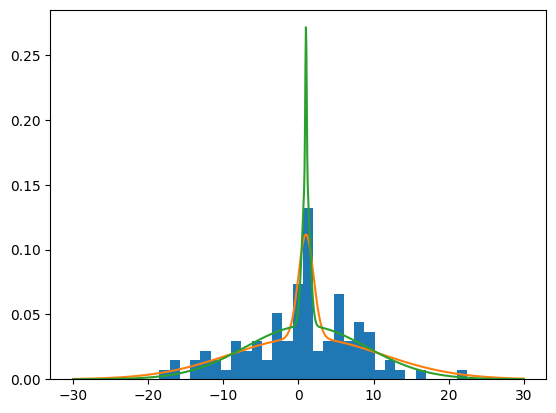

In [6]:
# visualization for NPMLE
rng = np.random.default_rng(42)

prior_atoms = [1, 10]
prior_weights = [0.2, 0.8]
mu = 1
n = 100
N_obs, true_sig = generate_data_from_prior(prior_atoms, prior_weights, mu, n, rng)
prior_atoms = np.asarray(prior_atoms, dtype=float)
prior_weights = np.asarray(prior_weights, dtype=float)
plt.hist(N_obs, bins = 30, density = True)
print(f"True LL={avg_loglikelihood(prior_atoms, prior_weights, mu, N_obs)}")

grid = np.linspace(-30,30,1000)
true_density = mixture_density(prior_atoms, prior_weights, mu, grid)
plt.plot(grid, true_density)

atoms, weights = npmle_heteroskedastic(N_obs, mu)
print(atoms, weights)
fitted_density = mixture_density(atoms, weights, mu, grid)
plt.plot(grid, fitted_density)
plt.show()

In [7]:
_, __, mu_hat = npmle_alternating_full(N_obs)
print(np.median(N_obs))

/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


iteration 1, mu_hat=1.0698750292753214, LL=-3.2995170745015088
iteration 2, mu_hat=1.0668054535337474, LL=-3.271598752825243
iteration 3, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 4, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 5, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 6, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 7, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 8, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 9, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 10, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 11, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 12, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 13, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 14, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 15, mu_hat=1.0668040574559439, LL=-3.2714862184687106
iteration 16, mu_hat=1.0668040574559439, LL=-3.271

## Does MLE with oracle knowledge of G recover $\mu$?

In [8]:
def LL_max(mu,N_obs):
    atoms, weights = npmle_heteroskedastic(N_obs, mu, si_min=0.1, verbose=False)
    return avg_loglikelihood(atoms, weights, mu, N_obs)

mu_grid = np.linspace(0,2,100)
LL_grid = np.array([LL_max(mu,N_obs) for mu in mu_grid])
mu_hat = mu_grid[np.argmax(LL_grid)]
print(mu_hat)
print(np.median(N_obs))

Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
Weight optimization failed. Increase maxls to  60
Weight optimization failed

In [ ]:
mu_grid = np.linspace(0,2,500)
LL_grid = np.array([avg_loglikelihood(prior_atoms, prior_weights, mu, N_obs) for mu in mu_grid])
mu_hat = mu_grid[np.argmax(LL_grid)]

est_opt = sum( N_obs / (true_sig ** 2) ) / sum(1 / (true_sig ** 2))
print(est_opt)
print(mu_hat)
print(np.median(N_obs))

1.0142664776922445
0.969939879759519
0.9743371170489201


In [ ]:
#sample_scale_mixture(0, prior_atoms, prior_weights, n=30)
si_min = 0.5
si_max = 15
n = 200
m = np.sqrt(n * np.log(n))

X = subset_of_signals_adversarial_prior(10, si_min, si_max, m, n)
B = 10.0
mu0 = 1
true_mu = 10

mu_hat = iterative_truncation_estimator(N_obs=X, B=B, mu0=mu0, mu_star=true_mu*2, m=m, return_path=False)
print("Estimated mean:", mu_hat)
print("m:", m)

Estimated mean: 10.028245290396812
m: 32.55247261437459


In [ ]:
# Still bugs with trying the npmmle-based estimator
# Only hyperparameters: si_min and si_max (for now)

npmle_alternating_full(X, si_min, si_max, iter_max = 10, verbose = True)

iteration 1, mu_hat=0.26716046559189444, LL=-3.3889356917214304


/tmp/ipython-input-1768622840.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/tmp/ipython-input-1768622840.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/tmp/ipython-input-1768622840.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/tmp/ipython-input-1768622840.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a sin

iteration 2, mu_hat=0.2617578065576434, LL=-3.38892086237493
iteration 3, mu_hat=0.2617578065576434, LL=-3.38892086237493


/tmp/ipython-input-1768622840.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/tmp/ipython-input-1768622840.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


iteration 4, mu_hat=0.2617578065576434, LL=-3.38892086237493
iteration 5, mu_hat=0.2617578065576434, LL=-3.38892086237493


...

/tmp/ipython-input-1768622840.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/tmp/ipython-input-1768622840.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


iteration 8, mu_hat=0.2617578065576434, LL=-3.38892086237493


/tmp/ipython-input-1768622840.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/tmp/ipython-input-1768622840.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


iteration 9, mu_hat=0.2617578065576434, LL=-3.38892086237493
iteration 10, mu_hat=0.2617578065576434, LL=-3.38892086237493


(array([ 0.8       ,  2.39358717,  2.450501  ,  7.62965932,  7.75510204,
        15.        ]),
 array([0.0790728 , 0.19130022, 0.04960229, 0.18378   , 0.36300569,
        0.13323899]),
 0.2617578065576434)

In [ ]:
# weights function not working

get_weights_npmle(atoms=np.array([5, 110]), weights=np.array([0.5, 0.5]), mu=0, N_obs=X)

(True, array([0.73021767, 0.26978233]))

## Code for the Heteroskedastic mean estimation via the NPMLE

In [9]:
############################ NPMLE estimator ##################################

# Should be a simultaneous minmization of (\hat{\mu}, \hat{G}) over grid space
# Using Frank-Wolfe algorithm
# Output for fixed obs the density of f_{G,mu}(obs)
def mixture_density(prior_atoms, prior_weights, mu, obs):
  k = len(prior_atoms)
  dens=0
  for i in range(k):
    dens += prior_weights[i]*stats.norm.pdf(x=obs, loc=mu, scale = prior_atoms[i])
  return dens

def avg_loglikelihood(prior_atoms, prior_weights, mu, N_obs):
  return (1/len(N_obs)) * np.sum([np.log(mixture_density(prior_atoms, prior_weights, mu, x)) for x in N_obs])

# gradient of D_{G}(\si;\mu)
"""
    Computes D_G(sigma^2; mu) = (1/n) sum_i [ (1/sigma)*phi((X_i-mu)/sigma) / f_G_mu(X_i) ]
    where f_G_mu(x) = sum_j w_j * N(x | mu, prior_atoms[j]).
"""
def grad(prior_atoms, prior_weights, sigma, mu, N_obs):
    # Standard normal pdf term (vectorized)
    num = (1.0 / sigma) * norm.pdf((N_obs - mu) / sigma)

    # Mixture density f_{G,mu}(x)
    denom = np.sum([
        w * norm.pdf(N_obs, loc=mu, scale=s2)
        for (w, s2) in zip(prior_weights, prior_atoms)
    ], axis=0)

    return np.mean(num / denom)

def update_atoms(atoms, weights, mu, N_obs):
  # Step 1: Take the gradient of the D_G(\si; \mu) function
  grad_fn = lambda x: grad(atoms, weights, x, mu, N_obs)-1
  X_min = np.min(N_obs)
  X_max = np.max(N_obs)
  # Step 2: Find roots of the gradient on the interval [si_min, si_max] of N_obs
  new_atom = root_scalar(grad_fn, bracket=(X_min,X_max), method='brentq').root
  if new_atom not in atoms:
    new_atoms = np.append(atoms, new_atom)
  else:
    new_atoms = atoms
  return new_atoms


def get_weights_npmle(atoms, weights, mu, N_obs):
  def target(weights):
    return avg_loglikelihood(atoms, weights, mu, N_obs)

  # NOTE: Increase maxls (default 20) helps to resolve ABNORMAL_TERMINATION_IN_LNSRCH error
  opt_success = False
  number_ls = 20
  opt_options = {'maxls': int(number_ls)} # default is 20.
  max_tries = 3
  iter = 0

  # Should the algorithm here forget the weights of the previous iteration? probably
  weights = np.ones(len(atoms))/len(atoms)

  while (not opt_success) and (iter < max_tries):
    result = sp.optimize.minimize(target, weights,
                               method='L-BFGS-B',tol=1e-6,
                               options=opt_options)
    if not result.success:
      number_ls *= 3
      print("Opt failed. Increase maxls to ", number_ls)
      opt_options = {'maxls': int(number_ls), 'maxfun': 1e6}
      iter += 1
    else:
      opt_success = True
    break

  if not opt_success:
      print("FW optimization failed")
      return opt_success, weights
  else:
      return opt_success, result.x / np.sum(result.x)

# alternative if FW fails
def get_weights_npmle_EM(x, scales, mu=0.0, w_init=None,
                             max_iter=200, tol=1e-8):
    """
    EM for a 1D Gaussian scale mixture with fixed mu and scales,
    optimizing only the mixture weights.

    Model: X ~ sum_k w_k * N(mu, scales[k]**2)

    Parameters
    ----------
    x : array_like, shape (n,)
        Observations.
    scales : array_like, shape (K,)
        Fixed standard deviations sigma_k > 0.
    mu : float
        Fixed location parameter.
    w_init : array_like, shape (K,), optional
        Initial weights; if None, use uniform.
    max_iter : int
        Maximum EM iterations.
    tol : float
        Stop when change in weights has L1 norm < tol.

    Returns
    -------
    w : ndarray, shape (K,)
        Estimated mixture weights (MLE).
    loglik_hist : list of float
        Log-likelihood values over iterations.
    """
    x = np.asarray(x, dtype=float)
    sigma = np.asarray(scales, dtype=float)
    n = x.size
    K = sigma.size

    if w_init is None:
        w = np.ones(K) / K
    else:
        w = np.asarray(w_init, dtype=float)
        w = w / w.sum()

    loglik_hist = []

    for _ in range(max_iter):
        # E-step: responsibilities r_{ik}
        # shape: (n, K)
        # Evaluate component densities at all data
        comp_dens = norm.pdf(x[:, None], loc=mu, scale=sigma[None, :])  # n x K
        numer = w[None, :] * comp_dens
        denom = numer.sum(axis=1, keepdims=True)  # n x 1
        r = numer / denom  # n x K

        # M-step: new weights
        w_new = r.mean(axis=0)  # K

        # log-likelihood (optional monitoring)
        loglik = np.sum(np.log(denom.squeeze()))
        loglik_hist.append(loglik)

        # convergence check
        if np.linalg.norm(w_new - w, ord=1) < tol:
            w = w_new
            break

        w = w_new

    return w

def npmle_heteroskedastic(N_obs, mu, si_min, si_max, atoms_init=None, weights_init = None, weight_tol = 1e-6, atom_tol = 1e-6, progress_tol = 1e-6, iter_max = 20, verbose = True):
  # initial mu: sample mean
  mu = np.mean(N_obs)

  # initial only if atoms_init/weights_init needed
  atoms_best = atoms_init
  weights_best = weights_init
  atoms = atoms_init
  weights = weights_init
  obj = avg_loglikelihood(atoms, weights, mu, N_obs)
  iter = 0
  if verbose:
    print(f"initial average LL={obj}")
  while iter < iter_max:
    start_time = time.time()
    # update atoms by discovering a new one
    atoms = update_atoms(atoms, weights, mu, N_obs)

    start_time = time.time()

    # update npmle weights searching only over support of adjusted atoms
    opt_success, weights = get_weights_npmle(atoms, weights, mu, N_obs)

    if not opt_success: # if FW failed, switch to EM for weight update
      # Corrected argument order: N_obs as x, atoms as scales, weights as w_init
      weights = get_weights_npmle_EM(x=N_obs, scales=atoms, mu=mu, w_init=weights, max_iter=2000)
    # merge atoms that are too close to each other
    atoms,weights = merge_atoms_weights(atoms,weights,atom_tol)

    # drop atoms with tiny weights
    mask = weights >= weight_tol
    atoms = atoms[mask]
    weights = weights[mask]

    # compute new objective value of the likelihood
    obj_new = avg_loglikelihood(atoms, weights, mu, N_obs)

    if obj_new > obj:
      atoms_best = atoms
      weights_best = weights
      obj = obj_new

    # check stopping criterion
    iter+=1
    if verbose:
      print(f"iteration {iter}, average LL={obj_new}")

    # # Final clean up
    # print(len(unique_elements))
    # L=len(unique_elements)+1
    # heavy_atom_indices = np.argsort(weights)[-L:]  # Indices of the top k weights
    # atoms = atoms[heavy_atom_indices]
    # weights = weights[heavy_atom_indices]
    # weights = weights /np.sum(weights)

    return atoms_best, weights_best


def mle_location_scale_mixture(N_obs, atoms, weights, mu_init=None):
    """
    MLE of the common location mu in a 1D Gaussian scale mixture:
        X ~ sum_k w_k * N(mu, scales[k]**2)

    Parameters
    ----------
    N_obs : array_like, shape (n,)
        Observations.
    scales : array_like, shape (K,)
        Positive scale atoms (standard deviations sigma_k).
    weights : array_like, shape (K,)
        Mixture weights (need not be normalized).
    mu_init : float, optional
        Initial guess for mu. Defaults to sample mean.

    Returns
    -------
    mu_hat : float
        MLE of the location parameter mu.
    result : OptimizeResult
        Full scipy optimization result (in case you want diagnostics).
    """
    x = np.asarray(N_obs, dtype=float)
    sigma = np.asarray(atoms, dtype=float)
    w = np.asarray(weights, dtype=float)

    # normalize weights
    w = w / w.sum()

    # precompute constants
    log_norm_const = -0.5 * np.log(2.0 * np.pi * sigma)  # shape (K,)

    n = x.size
    if mu_init is None:
        mu_init = float(x.mean())

    # negative log-likelihood
    def nll(mu):
        # shape (n, K)
        diff = x[:, None] - mu
        log_comp = log_norm_const[None, :] - (diff**2) / (2.0 * sigma[None, :])
        # mixture density f_i = sum_k w_k * N(x_i | mu, sigma_k^2)
        comp = np.exp(log_comp) * w[None, :]
        f = comp.sum(axis=1)  # shape (n,)
        if np.any(f <= 0):
            return np.inf
        return -np.sum(np.log(f))

    # gradient d/dmu (negative log-likelihood)
    def grad_nll(mu):
        diff = x[:, None] - mu
        log_comp = log_norm_const[None, :] - (diff**2) / (2.0 * sigma[None, :])
        comp = np.exp(log_comp) * w[None, :]
        f = comp.sum(axis=1)  # shape (n,)

        # d f_i / d mu = sum_k comp_{ik} * (x_i - mu) / sigma_k^2
        df_dmu = (comp * (diff / sigma[None, :])).sum(axis=1)  # shape (n,)
        # d/dmu (-log f_i) = - (1/f_i) df_i/dmu
        g = -np.sum(df_dmu / f)
        return np.array([g])  # scipy expects array-like

    res = minimize(
        fun=nll,
        x0=np.array([mu_init]),
        jac=grad_nll,
        method="BFGS",
    )

    mu_hat = float(res.x[0])
    return mu_hat, res

def npmle_alternating_full(N_obs, si_min, si_max, iter_max = 20):
  # For certain # of iterations, run full NPMLE update for a fixed mu, then update mu according to maximum likelihood
  # Initialize (mu_0, G_0) based on N_obs
  mu = np.mean(N_obs)
  N_max=np.max(N_obs)
  N_min=np.min(N_obs)
  grid_size=50
  atoms = np.linspace(N_min,N_max,grid_size)
  weights = np.ones(grid_size)/grid_size
  # print("randomly initalize weights")
  # weights = np.random.rand(grid_size)
  # weights = weights/np.sum(weights)

  for _ in range(iter_max):
    atoms, weights = npmle_heteroskedastic(N_obs, mu, si_min, si_max, atoms_init=atoms, weights_init=weights, weight_tol = 1e-6, atom_tol = 1e-6, progress_tol = 1e-6, iter_max = 20, verbose = True)
    mu = mle_location_scale_mixture(N_obs, atoms, weights, mu_init=mu)[0]
  return atoms, weights

## Experiment: SOS model where $\mu^\ast = 0$, $\sigma_{\text{min}} = 0.8$, $\sigma_{\text{max}} = 15$, and $n=500$ samples

* Comparing the median estimator (without $k$ hyperparamter tuning), the iterative truncation estimator (also without hyperparameter tuning), and the NPMLE estimator, which is tuning parameter free.

/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


Completed simulation 10/10


/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/2844340141.py:66: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


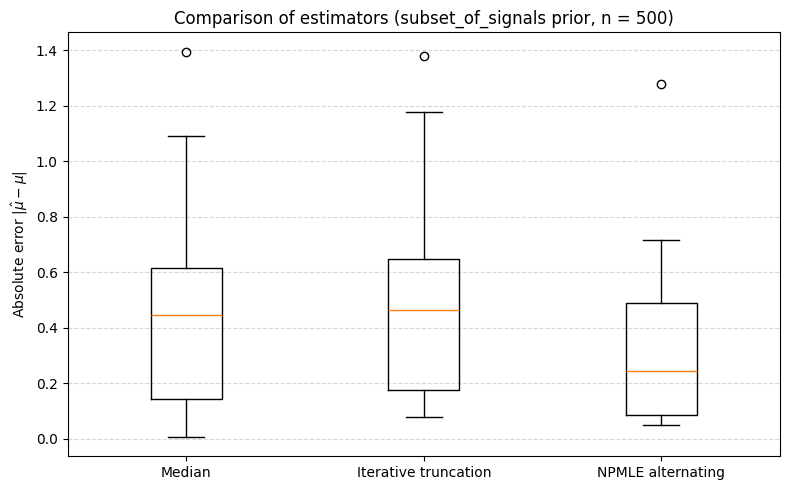

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Experiment parameters
n_sims = 10
si_min = 0.7
si_max = 150
n = 1000
m = 8
# m = np.sqrt(n * np.log(n))
# m = cube root(n)
true_mu = 2.0
B = 10.0      # for iterative_truncation_estimator
mu0 = 1.0     # initial guess for iterative_truncation_estimator

np.random.seed(0)

# Arrays to store absolute errors |mu_hat - true_mu|
err_median = np.zeros(n_sims)
err_iter   = np.zeros(n_sims)
err_npmle  = np.zeros(n_sims)

for s in range(n_sims):
    # 1. Generate data X from the subset_of_signals prior, as in the example:
    #    X = subset_of_signals_adversarial_prior(0, si_min, si_max, m, n)
    X = subset_of_signals_adversarial_prior(mu=true_mu,
                                            si_min=si_min,
                                            si_max=si_max,
                                            m=m,
                                            n=n)

    # 2. Median estimator
    mu_hat_median = median_estimator(X)

    # 3. Iterative truncation estimator
    mu_hat_iter = iterative_truncation_estimator(
        N_obs=X,
        B=B,
        mu0=mu0,
        mu_star=true_mu,   # only used in assumptions; harmless to pass
        m=m,
        n=n,
        return_path=False
    )

    # 4. NPMLE alternating estimator (scale mixture + mu)
    #    npmle_alternating_full returns (atoms, weights, mu_hat)
    atoms_hat, weights_hat, mu_hat_npmle = npmle_alternating_full(
        N_obs=X,
        si_min=si_min,
        si_max=si_max,
        iter_max=12,
        verbose=False
    )

    # 5. Record absolute errors
    err_median[s] = np.abs(mu_hat_median - true_mu)
    err_iter[s]   = np.abs(mu_hat_iter   - true_mu)
    err_npmle[s]  = np.abs(mu_hat_npmle  - true_mu)

    if (s + 1) % 10 == 0:
        print(f"Completed simulation {s+1}/{n_sims}")

# 6. Boxplot of the absolute errors
plt.figure(figsize=(8, 5))
plt.boxplot(
    [err_median, err_iter, err_npmle],
    labels=["Median", "Iterative truncation", "NPMLE alternating"]
)
plt.ylabel(r"Absolute error $|\hat{\mu} - \mu|$")
plt.title("Comparison of estimators (subset_of_signals prior, n = 500)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
print(f"median: {err_median}")
print(f"npmle: {err_npmle}")
print(f"IT: {err_iter}")

median: [0.3132866  0.01296284 0.22171507 0.19682272 0.21027248 0.18259248
 0.30047016 0.14661561 0.3475409  0.41012701]
npmle: [0.16428119 0.18833966 0.0254742  0.32520188 0.15858224 0.03507463
 0.46184833 0.43302863 0.52541129 0.30253492]
IT: [0.29211159 0.05497929 0.35624344 0.01700757 0.22746853 0.14579419
 0.34699116 0.25732972 0.36100631 0.34176795]


In [ ]:
# Running the cube root version

import numpy as np
import matplotlib.pyplot as plt

# Experiment parameters
n_sims = 1
si_min = 0.8
si_max = 15.0
n = 500
# m = np.sqrt(n * np.log(n))
m = np.cbrt(n)
true_mu = 0.0
B = 10.0      # for iterative_truncation_estimator
mu0 = 1.0     # initial guess for iterative_truncation_estimator

np.random.seed(0)

# Arrays to store absolute errors |mu_hat - true_mu|
err_median = np.zeros(n_sims)
err_iter   = np.zeros(n_sims)
err_npmle  = np.zeros(n_sims)

for s in range(n_sims):
    # 1. Generate data X from the subset_of_signals prior, as in the example:
    #    X = subset_of_signals_adversarial_prior(0, si_min, si_max, m, n)
    X = subset_of_signals_adversarial_prior(mu=true_mu,
                                            si_min=si_min,
                                            si_max=si_max,
                                            m=m,
                                            n=n)

    # 2. Median estimator
    mu_hat_median = median_estimator(X)

    # 3. Iterative truncation estimator
    mu_hat_iter = iterative_truncation_estimator(
        N_obs=X,
        B=B,
        mu0=mu0,
        mu_star=true_mu,   # only used in assumptions; harmless to pass
        m=m,
        n=n,
        return_path=False
    )

    # 4. NPMLE alternating estimator (scale mixture + mu)
    #    npmle_alternating_full returns (atoms, weights, mu_hat)
    atoms_hat, weights_hat, mu_hat_npmle = npmle_alternating_full(
        N_obs=X,
        si_min=si_min,
        si_max=si_max,
        iter_max=12
    )

    # 5. Record absolute errors
    err_median[s] = np.abs(mu_hat_median - true_mu)
    err_iter[s]   = np.abs(mu_hat_iter   - true_mu)
    err_npmle[s]  = np.abs(mu_hat_npmle  - true_mu)

    if (s + 1) % 10 == 0:
        print(f"Completed simulation {s+1}/{n_sims}")

# 6. Boxplot of the absolute errors
plt.figure(figsize=(8, 5))
plt.boxplot(
    [err_median, err_iter, err_npmle],
    labels=["Median", "Iterative truncation", "NPMLE alternating"]
)
plt.ylabel(r"Absolute error $|μ - μ|$ ")
plt.title("Comparison of estimators (subset_of_signals prior, n = 500)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

initial average LL=nan
Opt failed. Increase maxls to  60
FW optimization failed


: 

## Line Plot Comparison: Error vs Sample Size (n from $10^2$ to $10^4$)

This experiment compares the three estimators (Median, Iterative Truncation, NPMLE) across different sample sizes with error bars. The plot uses a log-log scale.

In [ ]:
# Experiment parameters
n_values = np.logspace(2, 4, 12).astype(int)  # 12 points from 10^2 to 10^6
n_sims = 20  # Number of simulations per n value (for computing mean and std)

# Prior parameters
si_min = 0.7
si_max = 150
true_mu = 2.0

# Truncation estimator parameters
B = 10.0
mu0 = 1.0

# Storage for results
results_median = {n: [] for n in n_values}
results_truncation = {n: [] for n in n_values}
results_npmle = {n: [] for n in n_values}

np.random.seed(42)

print(f"Running experiment with n values: {n_values}")
print(f"Number of simulations per n: {n_sims}")
print("="*60)

for n in n_values:
    print(f"\nProcessing n = {n:,}...")
    m = max(1, int(np.sqrt(n * np.log(n))))  # m = cube root of n
    
    for s in range(n_sims):
        # Generate data
        X = subset_of_signals_adversarial_prior(
            mu=true_mu, si_min=si_min, si_max=si_max, m=m, n=n)
        
        # 1. Median estimator
        mu_hat_median = median_estimator(X)
        err_median = np.abs(mu_hat_median - true_mu)
        results_median[n].append(err_median)
        
        # 2. Iterative truncation estimator
        mu_hat_trunc = iterative_truncation_estimator(
            N_obs=X, B=B, mu0=mu0, mu_star=true_mu, m=m, n=n, return_path=False)
        err_trunc = np.abs(mu_hat_trunc - true_mu)
        results_truncation[n].append(err_trunc)
        
        # 3. NPMLE estimator (skip for very large n due to computational cost)
        if n <= 1e6:  # Only run NPMLE for n <= 10^6
            try:
                _, _, mu_hat_npmle = npmle_alternating_full(
                    N_obs=X, si_min=si_min, si_max=si_max, 
                    iter_max=8, verbose=False)
                err_npmle = np.abs(mu_hat_npmle - true_mu)
            except Exception as e:
                err_npmle = np.nan
        else:
            err_npmle = np.nan
        results_npmle[n].append(err_npmle)
        
    print(f"  Completed {n_sims} simulations for n = {n:,}")

print("\n" + "="*60)
print("Experiment complete!")

Running experiment with n values: [  100   151   231   351   533   811  1232  1873  2848  4328  6579 10000]
Number of simulations per n: 20

Processing n = 100...


/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
  Completed 20 simulations for n = 100

Processing n = 151...
  Completed 20 simulations for n = 151

Processing n = 231...
  Completed 20 simulations for n = 231

Processing n = 351...
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
  Completed 20 simulations for n = 351

Processing n = 533...


In [ ]:
# Compute mean and standard error for each estimator at each n
def compute_stats(results_dict, n_values):
    means = []
    stds = []
    for n in n_values:
        vals = np.array(results_dict[n])
        vals = vals[~np.isnan(vals)]  # Remove NaN values
        if len(vals) > 0:
            means.append(np.mean(vals))
            stds.append(np.std(vals) / np.sqrt(len(vals)))  # Standard error
        else:
            means.append(np.nan)
            stds.append(np.nan)
    return np.array(means), np.array(stds)

median_means, median_stds = compute_stats(results_median, n_values)
trunc_means, trunc_stds = compute_stats(results_truncation, n_values)
npmle_means, npmle_stds = compute_stats(results_npmle, n_values)

print("Statistics computed successfully!")
print(f"\nMedian estimator - Mean errors: {median_means}")
print(f"Truncation estimator - Mean errors: {trunc_means}")
print(f"NPMLE estimator - Mean errors: {npmle_means}")

Statistics computed successfully!

Median estimator - Mean errors: [0.66577444 0.44553063 0.28957173 0.29298772 0.22326515 0.25490049
 0.21116291 0.24786604 0.21847544 0.14509951 0.13657576 0.21176383]
Truncation estimator - Mean errors: [0.66746339 0.41288812 0.28975775 0.30101683 0.2311506  0.25816954
 0.21318722 0.25199194 0.22789562 0.15332738 0.14413123 0.22601156]
NPMLE estimator - Mean errors: [0.18825606 0.16740609 0.14137199 0.11184998 0.10220669 0.11459347
 0.06717397 0.11855634 0.10333332 0.06162142 0.05862478 0.05651502]


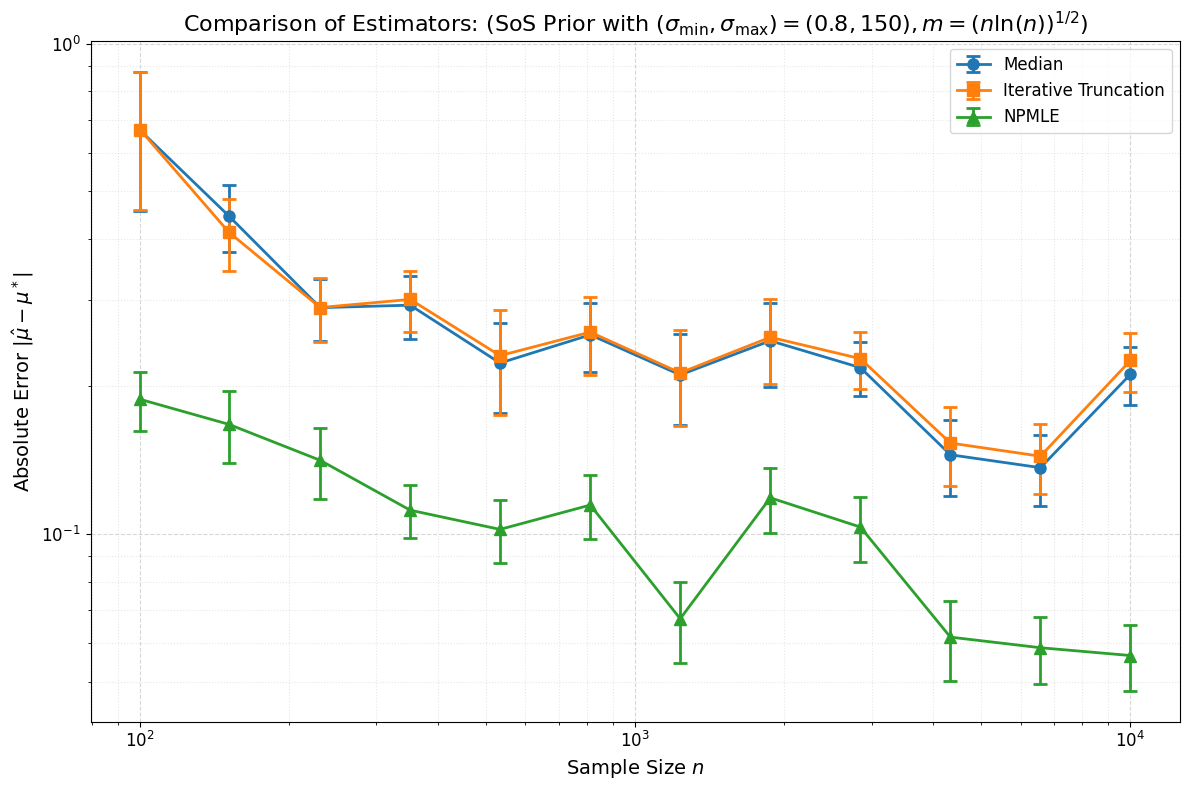


Plot saved to: estimator_comparison_loglog.png


In [ ]:
# Create the line plot with error bars on log-log scale
fig, ax = plt.subplots(figsize=(12, 8))

# Define colors for each estimator
colors = {
    'median': '#1f77b4',      # Blue
    'truncation': '#ff7f0e',  # Orange
    'npmle': '#2ca02c'        # Green
}

# Plot Median estimator
ax.errorbar(n_values, median_means, yerr=median_stds, 
            fmt='o-', color=colors['median'], linewidth=2, markersize=8,
            capsize=5, capthick=2, label='Median', elinewidth=2)

# Plot Truncation estimator
ax.errorbar(n_values, trunc_means, yerr=trunc_stds,
            fmt='s-', color=colors['truncation'], linewidth=2, markersize=8,
            capsize=5, capthick=2, label='Iterative Truncation', elinewidth=2)

# Plot NPMLE estimator (only where data exists)
valid_npmle = ~np.isnan(npmle_means)
ax.errorbar(n_values[valid_npmle], npmle_means[valid_npmle], 
            yerr=npmle_stds[valid_npmle],
            fmt='^-', color=colors['npmle'], linewidth=2, markersize=8,
            capsize=5, capthick=2, label='NPMLE', elinewidth=2)

# Set log scale for both axes
ax.set_xscale('log')
ax.set_yscale('log')

# Labels and title
ax.set_xlabel('Sample Size $n$', fontsize=14)
ax.set_ylabel(r'Absolute Error $|\hat{\mu} - \mu^*|$', fontsize=14)
ax.set_title(r'Comparison of Estimators: (SoS Prior with $(\sigma_{\text{min}}, \sigma_{\text{max}})=(0.8,150), m=(n\ln(n))^{1/2}$)', fontsize=16)

# Legend
ax.legend(fontsize=12, loc='upper right')

# Grid
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', linestyle=':', alpha=0.3)

# Tick formatting
ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('estimator_comparison_loglog.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nPlot saved to: estimator_comparison_loglog.png")

## MLE with Known G vs NPMLE with Unknown G (Two-Point Prior)

Compare the MLE estimator when the prior $G$ (and thus the $\sigma_i$'s) is known:
$$\hat{\mu}_{\text{known}-\sigma} = \frac{\sum_{i=1}^{n} \frac{X_i}{\sigma_i^2}}{\sum_{i=1}^{n} \frac{1}{\sigma_i^2}}$$

versus the NPMLE estimator when $G$ is unknown.

In [ ]:
# MLE estimator with known variances (known G)
def mle_known_sigma(X, sigma):
    """
    MLE estimator for mu when the variances sigma_i^2 are known.
    
    Parameters:
    -----------
    X : array of observations
    sigma : array of known standard deviations for each observation
    
    Returns:
    --------
    mu_hat : MLE estimate of mu
    """
    X = np.asarray(X, dtype=float)
    sigma = np.asarray(sigma, dtype=float)
    
    # Compute weights = 1/sigma_i^2
    weights = 1.0 / (sigma ** 2)
    
    # MLE = sum(X_i / sigma_i^2) / sum(1 / sigma_i^2)
    mu_hat = np.sum(X * weights) / np.sum(weights)
    
    return mu_hat

Test MLE with known sigma: 2.0000


In [46]:
# Experiment: MLE (known G) vs NPMLE (unknown G) for Two-Point Prior

# Experiment parameters
n_values_2pt = np.logspace(2, 4, 12).astype(int)  # 12 points from 10^2 to 10^8
n_sims_2pt = 20  # Number of simulations per n value

# Two-point prior parameters
prior_atoms = np.array([1.0, 30.0])    # Two scale values: sigma_1 = 1, sigma_2 = 10
prior_weights = np.array([0.01, 0.99])   

# Storage for results
results_mle_known = {n: [] for n in n_values_2pt}
results_npmle_unknown = {n: [] for n in n_values_2pt}
# results_median_2pt = {n: [] for n in n_values_2pt}

np.random.seed(42)

print(f"Two-Point Prior: atoms = {prior_atoms}, weights = {prior_weights}")
print(f"True mu = {true_mu}")
print(f"Running experiment with n values: {n_values_2pt}")
print(f"Number of simulations per n: {n_sims_2pt}")
print("="*60)

for n in n_values_2pt:
    print(f"\nProcessing n = {n:,}...")
    
    for s in range(n_sims_2pt):
        # Generate data from two-point prior (returns both X and true sigmas)
        X, true_sigmas = generate_data_from_prior(prior_atoms, prior_weights, true_mu, n)
        
        # 1. MLE with known G (known sigmas)
        mu_hat_mle_known = mle_known_sigma(X, true_sigmas)
        err_mle_known = np.abs(mu_hat_mle_known - true_mu)
        results_mle_known[n].append(err_mle_known)

        # 2. NPMLE estimator (unknown G) - skip for very large n
        if n <= 1e6:
            try:
                _, _, mu_hat_npmle = npmle_alternating_full(
                    N_obs=X, 
                    si_min=0.5,  # Lower bound for scale search
                    si_max=100.0, # Upper bound for scale search
                    iter_max=8, 
                    verbose=False)
                err_npmle = np.abs(mu_hat_npmle - true_mu)
            except Exception as e:
                err_npmle = np.nan
        else:
            err_npmle = np.nan
        results_npmle_unknown[n].append(err_npmle)
        
    print(f"  Completed {n_sims_2pt} simulations for n = {n:,}")

print("\n" + "="*60)
print("Experiment complete!")

Two-Point Prior: atoms = [ 1. 30.], weights = [0.01 0.99]
True mu = 0
Running experiment with n values: [  100   151   231   351   533   811  1232  1873  2848  4328  6579 10000]
Number of simulations per n: 20

Processing n = 100...


/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:499: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)
/var/folders/ds/86h9krvs03g7j5pwtjnvl65r0000gp/T/ipykernel_62729/1837750654.py:510: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mu = float(mu)


Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
  Completed 20 simulations for n = 100

Processing n = 151...
  Completed 20 simulations for n = 151

Processing n = 231...
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) failed; falling back to EM or previous weights.
Weight optimization failed. Increase maxls to  60
Weight optimization failed. Increase maxls to  180
Weight optimization failed. Increase maxls to  540
Weight optimization (L-BFGS-B) 

In [47]:
# Compute statistics for MLE vs NPMLE comparison
mle_known_means, mle_known_stds = compute_stats(results_mle_known, n_values_2pt)
npmle_unknown_means, npmle_unknown_stds = compute_stats(results_npmle_unknown, n_values_2pt)
# median_2pt_means, median_2pt_stds = compute_stats(results_median_2pt, n_values_2pt)

print("Statistics computed successfully!")
print(f"\nMLE (known G) - Mean errors: {mle_known_means}")
print(f"NPMLE (unknown G) - Mean errors: {npmle_unknown_means}")
# print(f"Median - Mean errors: {median_2pt_means}")

Statistics computed successfully!

MLE (known G) - Mean errors: [1.6811592  0.66567282 0.76606048 0.51570878 0.49376142 0.31035015
 0.22330639 0.13662211 0.18060559 0.14157337 0.10285148 0.11004494]
NPMLE (unknown G) - Mean errors: [2.86474994 1.34207261 1.8713466  1.09912389 1.1155675  0.84941129
 0.56271056 0.40015549 0.3170027  0.20814243 0.23503878 0.22661166]


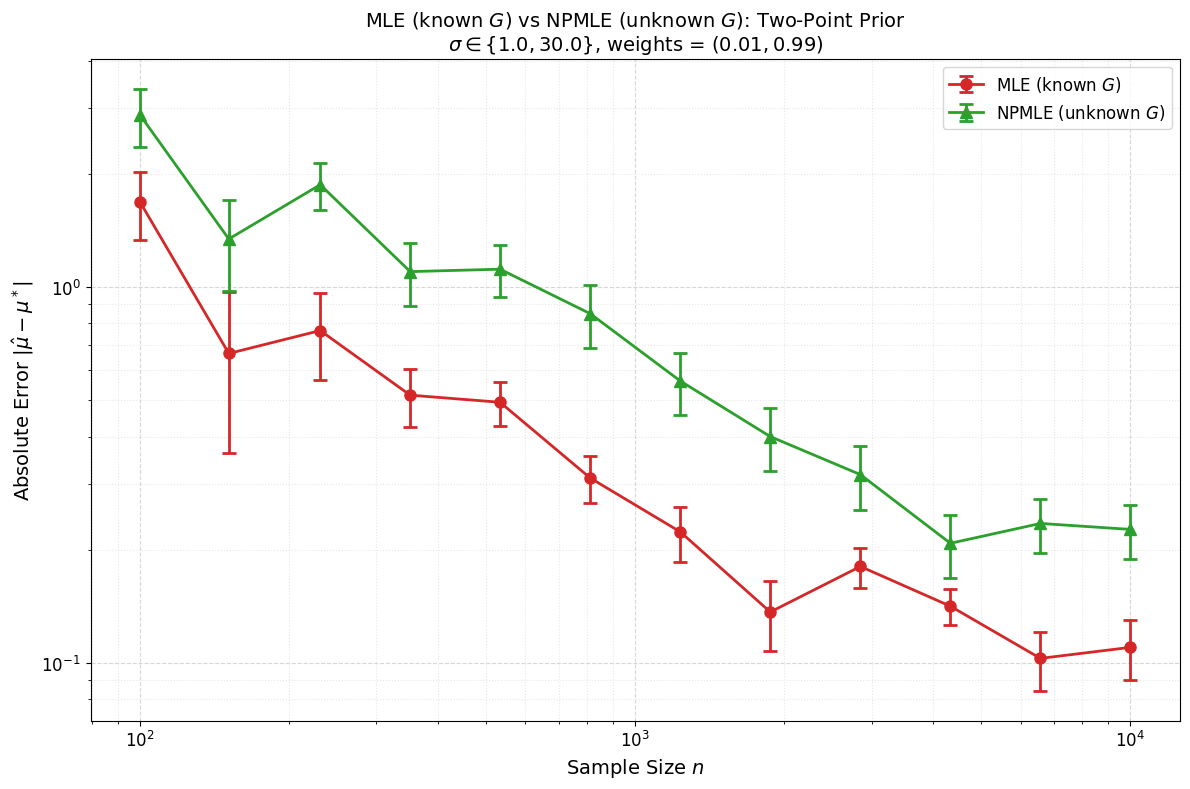


Plot saved to: mle_vs_npmle_two_point_prior.png


In [48]:
# Create the line plot: MLE (known G) vs NPMLE (unknown G) on log-log scale
fig, ax = plt.subplots(figsize=(12, 8))

# Define colors
colors = {
    'mle_known': '#d62728',   # Red - MLE with known G (oracle)
    'npmle': '#2ca02c',       # Green - NPMLE
    'median': '#1f77b4'       # Blue - Median (baseline)
}

# Plot MLE with known G (oracle estimator)
ax.errorbar(n_values_2pt, mle_known_means, yerr=mle_known_stds, 
            fmt='o-', color=colors['mle_known'], linewidth=2, markersize=8,
            capsize=5, capthick=2, label='MLE (known $G$)', elinewidth=2)

# Plot NPMLE (unknown G) - only where data exists
valid_npmle = ~np.isnan(npmle_unknown_means)
ax.errorbar(n_values_2pt[valid_npmle], npmle_unknown_means[valid_npmle], 
            yerr=npmle_unknown_stds[valid_npmle],
            fmt='^-', color=colors['npmle'], linewidth=2, markersize=8,
            capsize=5, capthick=2, label='NPMLE (unknown $G$)', elinewidth=2)

# Set log scale for both axes
ax.set_xscale('log')
ax.set_yscale('log')

# Labels and title
ax.set_xlabel('Sample Size $n$', fontsize=14)
ax.set_ylabel(r'Absolute Error $|\hat{\mu} - \mu^*|$', fontsize=14)
ax.set_title(f'MLE (known $G$) vs NPMLE (unknown $G$): Two-Point Prior\n'
             f'$\\sigma \\in \\{{{prior_atoms[0]}, {prior_atoms[1]}\\}}$, '
             f'weights = $({prior_weights[0]}, {prior_weights[1]})$', fontsize=14)

# Legend
ax.legend(fontsize=12, loc='upper right')

# Grid
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', linestyle=':', alpha=0.3)

# Tick formatting
ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('mle_vs_npmle_two_point_prior.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nPlot saved to: mle_vs_npmle_two_point_prior.png")